# 01. Lead time and false-alarm cost of alert rules, and the one-minute spot cache

I build the one-minute Binance spot BTCUSDT cache that the later notebooks read. I then optimize alert thresholds for a hypothetical cost of missed events, false alerts and late alerts under an alert budget, and compare spectral and volatility rules with the same inputs and definitions.

- The data are Binance spot BTCUSDT one-minute klines, 76 monthly archives from 2020-01 to 2026-04 published on data.binance.vision.
- I use the signals and event definition of the baseline BTC study. I optimize thresholds on 2021–2022 only, hold them fixed and apply them to 2023–2024. I skip the 2025-01 to 2026-09 period, which runs past the end of the cache in April 2026.
- This analysis is exploratory and retrospective. Costs are hypothetical cost points, not money. I already examined the 2023–2026 data in the baseline study, so they are not an untouched holdout.
- I write results to the top level of `MyDrive/btc_lead_cost_results_77months_spot/`, the caches to `cache/` and the selected rules to `selected_rules_2021_2022.json`, which notebook 02 reads.


## Pipeline and definitions

I merge the monthly files onto the one-minute grid, compute the features and event labels of the baseline study, optimize thresholds under a cost constraint on the training period, and compare them with the volatility rule on the later periods.

- The input is Binance spot BTCUSDT one-minute bars with `open_time`, OHLC, `volume` and `taker_buy_base_asset_volume`.
- I keep the definitions of the baseline study: 4% fall, 5-minute persistence, 4-hour horizon, 4-hour cooldown and event-level one-to-one matching.
- For the low-volatility regime of the baseline study (24-hour realized volatility and range, against their trailing 180-day 40% quantiles), I compute an exact rolling quantile.

## 1. Google Drive and settings
I keep the spot archives in `MyDrive/BTCUSDT_spot/1m/` and write results and caches to `btc_lead_cost_results_77months_spot`.

In [1]:
from pathlib import Path
import os, re, sys, zipfile, gzip, io, json, gc, hashlib, warnings
import numpy as np
import pandas as pd
from IPython.display import display

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip -q install numba pyarrow

DATA_FOLDER = Path('/content/drive/MyDrive/BTCUSDT_spot')   # folder for the monthly spot ZIPs downloaded by this notebook
WORK_DIR = Path('/content/btc_cost_work')              # local Colab scratch space
OUT_DIR = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
OUTPUT_DIR = str(OUT_DIR)   # string form of OUT_DIR, used with os.path
CACHE_DIR = OUT_DIR / 'cache'
for p in [DATA_FOLDER, WORK_DIR, OUT_DIR, CACHE_DIR]: p.mkdir(parents=True, exist_ok=True)
print('Raw data folder:',DATA_FOLDER)
print('Results folder:',OUT_DIR)

Mounted at /content/drive
Raw data folder: /content/drive/MyDrive/BTCUSDT_spot
Results folder: /content/drive/MyDrive/btc_lead_cost_results_77months_spot


## 2. Binance spot one-minute archives
Here I take the 76 monthly spot archives for 2020-01 to 2026-04 from `data.binance.vision/data/spot/...`.

In [2]:
import urllib.request, urllib.error, time
SPOT_URL='https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-{ym}.zip'
FIRST_MONTH, LAST_MONTH = '2020-01', '2026-04'
RAW_DIR = DATA_FOLDER/'1m'
RAW_DIR.mkdir(parents=True, exist_ok=True)

def _fetch(url, tries=5):
    last=None
    for k in range(tries):
        try:
            req=urllib.request.Request(url, headers={'User-Agent':'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code==404: return None
            last=e
        except Exception as e:
            last=e
        time.sleep(2**k)
    raise RuntimeError(f'Download failed: {url} ({last})')

dl_rows=[]
for ym in [p.strftime('%Y-%m') for p in pd.period_range(FIRST_MONTH, LAST_MONTH, freq='M')]:
    url=SPOT_URL.format(ym=ym)
    dest=RAW_DIR/f'BTCUSDT-1m-{ym}.zip'
    chk=_fetch(url+'.CHECKSUM')
    if chk is None:
        raise RuntimeError(f'{ym}: no checksum file for the spot archive: {url}.CHECKSUM')
    expected=chk.decode().split()[0].strip().lower()
    if dest.is_file() and hashlib.sha256(dest.read_bytes()).hexdigest()==expected:
        status='cached'
    else:
        data=_fetch(url)
        if data is None:
            raise RuntimeError(f'{ym}: spot archive not found: {url}')
        if hashlib.sha256(data).hexdigest()!=expected:
            raise RuntimeError(f'SHA-256 mismatch: {url}')
        part=dest.parent/(dest.name+'.part')
        part.write_bytes(data); part.replace(dest)
        status='downloaded'
    dl_rows.append({'month':ym,'venue':'spot','url':url,'sha256':expected,'bytes':dest.stat().st_size,'status':status})
    if ym.endswith('-01') or ym==LAST_MONTH: print(ym, status, flush=True)
dl_manifest=pd.DataFrame(dl_rows)
dl_manifest.to_csv(OUT_DIR/'spot_download_manifest.csv',index=False)
print('Spot archives verified:',len(dl_manifest),'| status:',dl_manifest.status.value_counts().to_dict())


2020-01 downloaded
2021-01 downloaded
2022-01 downloaded
2023-01 downloaded
2024-01 downloaded
2025-01 downloaded
2026-01 downloaded
2026-04 downloaded
Spot archives verified: 76 | status: {'downloaded': 76}


## 3. Monthly file inventory

In [3]:
from collections import Counter

def supported(p):
    s=p.name.lower()
    return s.endswith(('.csv','.zip','.csv.gz','.parquet')) and 'checksum' not in s and 'manifest' not in s
monthly_files=sorted(p for p in DATA_FOLDER.rglob('*') if p.is_file() and supported(p))
print('Raw data files to read:',len(monthly_files))
print('File extensions:',Counter('.csv.gz' if p.name.lower().endswith('.csv.gz') else p.suffix.lower() for p in monthly_files))
print('First 5:',*[p.name for p in monthly_files[:5]],sep='\n  ')
print('Last 5:',*[p.name for p in monthly_files[-5:]],sep='\n  ')
months=[]
for p in monthly_files:
    mt=re.search(r'(20\d\d)[-_](0[1-9]|1[0-2])',p.name)
    if mt: months.append(f'{mt.group(1)}-{mt.group(2)}')
if months:
    missing=sorted(set(str(x) for x in pd.period_range(min(months),max(months),freq='M'))-set(months))
    print(f'Months in file names: {min(months)} to {max(months)}, apparently missing months: {missing[:30]}')
expected_names={f'BTCUSDT-1m-{m}.zip' for m in dl_manifest.month}
found_names={p.name for p in monthly_files}
if found_names!=expected_names:
    raise RuntimeError(f'{DATA_FOLDER} holds files that differ from the spot download list (futures files must not be mixed in). '
                       f'Extra files: {sorted(found_names-expected_names)[:5]}, missing files: {sorted(expected_names-found_names)[:5]}')
print('Folder contents match the spot download list exactly:',len(found_names),'files')
assert monthly_files, 'No CSV/ZIP/Parquet files to read. Run again once the files are in place.'

Raw data files to read: 76
File extensions: Counter({'.zip': 76})
First 5:
  BTCUSDT-1m-2020-01.zip
  BTCUSDT-1m-2020-02.zip
  BTCUSDT-1m-2020-03.zip
  BTCUSDT-1m-2020-04.zip
  BTCUSDT-1m-2020-05.zip
Last 5:
  BTCUSDT-1m-2025-12.zip
  BTCUSDT-1m-2026-01.zip
  BTCUSDT-1m-2026-02.zip
  BTCUSDT-1m-2026-03.zip
  BTCUSDT-1m-2026-04.zip
Months in file names: 2020-01 to 2026-04, apparently missing months: []
Folder contents match the spot download list exactly: 76 files


## 4. Monthly merge and the one-minute grid
I merge the monthly files onto a regular one-minute grid and keep the last record of any minute that appears in more than one file.

In [4]:
FULL_COLS=['open_time','open','high','low','close','volume','close_time','quote_asset_volume','number_of_trades','taker_buy_base_asset_volume','taker_buy_quote_asset_volume','ignore']
MAP={'timestamp':'open_time','time':'open_time','date':'open_time','datetime':'open_time','taker_buy_base_asset_volume':'taker_buy_vol','taker_buy_volume':'taker_buy_vol','taker_buy_vol':'taker_buy_vol'}
REQ=['open_time','open','high','low','close','volume','taker_buy_vol']

def parse_utc_time(s):
    numeric=pd.to_numeric(s,errors='coerce')
    ratio=float(numeric.notna().mean())
    if ratio>.95:
        median=float(numeric.abs().median())
        unit='ns' if median>1e17 else ('us' if median>1e14 else ('ms' if median>1e11 else 's'))
        return pd.to_datetime(numeric,unit=unit,utc=True,errors='coerce')
    return pd.to_datetime(s,utc=True,errors='coerce')

def parse_raw_table(df, source_name):
    if df.shape[1]>=10 and str(df.iloc[0,0]).strip().lower() not in ('open_time','timestamp','time'):
        df=df.iloc[:,[0,1,2,3,4,5,9]].copy()
        df.columns=REQ
    else:
        first=df.iloc[0].astype(str).str.strip().str.lower().tolist()
        if 'open_time' in first or 'timestamp' in first or 'time' in first:
            df.columns=[str(x).strip().lower() for x in df.iloc[0].tolist()]
            df=df.iloc[1:].copy()
        elif df.shape[1] == 12:
            df.columns=FULL_COLS
        else:
            raise ValueError(f'{source_name}: unexpected column layout: {df.shape[1]} columns, first row {first[:8]}')
        df=df.rename(columns=MAP)
        missing=[c for c in REQ if c not in df.columns]
        if missing: raise ValueError(f'{source_name}: required columns missing {missing}, found {df.columns.tolist()}')
        df=df[REQ].copy()
    df['open_time']=parse_utc_time(df['open_time'])
    for c in REQ[1:]: df[c]=pd.to_numeric(df[c],errors='coerce')
    return df.dropna(subset=['open_time'])

def read_monthly(path):
    if path.name.lower().endswith('.parquet'):
        t=pd.read_parquet(path)
        if isinstance(t.index,pd.DatetimeIndex) and 'open_time' not in t.columns:
            t=t.reset_index().rename(columns={t.index.name or 'index':'open_time'})
        t.columns=[str(x).strip().lower() for x in t.columns]
        t=t.rename(columns=MAP)
        missing=[c for c in REQ if c not in t.columns]
        if missing: raise ValueError(f'{path.name}: Parquet columns missing {missing}')
        t=t[REQ]
        t['open_time']=parse_utc_time(t.open_time)
        for c in REQ[1:]: t[c]=pd.to_numeric(t[c],errors='coerce')
        return t.dropna(subset=['open_time'])
    if path.suffix.lower()=='.zip':
        with zipfile.ZipFile(path) as z:
            members=[m for m in z.namelist() if m.lower().endswith('.csv') and not m.startswith('__MACOSX/')]
            if len(members)!=1:
                raise ValueError(f'{path.name}: {len(members)} CSV files in the ZIP; it must hold exactly one monthly CSV.')
            with z.open(members[0]) as f: df=pd.read_csv(f,header=None,low_memory=False)
    else:
        df=pd.read_csv(path,header=None,low_memory=False,compression='infer')
    if df.empty: raise ValueError(f'{path.name}: empty file')
    return parse_raw_table(df,path.name)

cache_merged=CACHE_DIR/'BTCUSDT_1m_regularized.parquet'
if cache_merged.exists():
    btc=pd.read_parquet(cache_merged)
    print('Reusing the merged data:',len(btc),'minutes')
else:
    pieces=[]; log=[]
    for i,p in enumerate(monthly_files,1):
        x=read_monthly(p)
        log.append({'file':str(p.relative_to(DATA_FOLDER)),'rows':len(x),
                    'first_utc':str(x.open_time.min()),'last_utc':str(x.open_time.max())})
        pieces.append(x)
        if i==1 or i%10==0 or i==len(monthly_files): print(f'[{i}/{len(monthly_files)}] {p.name}: {len(x):,} rows',flush=True)
    pd.DataFrame(log).to_csv(OUT_DIR/'monthly_file_manifest.csv',index=False)
    raw=pd.concat(pieces,ignore_index=True)
    del pieces;gc.collect()
    raw=raw.sort_values('open_time',kind='stable')
    dups=int(raw.open_time.duplicated().sum())
    raw=raw.drop_duplicates(subset='open_time',keep='last').set_index('open_time').sort_index()
    before=len(raw)
    full_idx=pd.date_range(raw.index.min(),raw.index.max(),freq='min',tz='UTC')
    btc=raw.reindex(full_idx)
    btc.index.name='open_time'
    # Gap policy: only fill missing runs of at most five minutes.
    missing=~full_idx.isin(raw.index)
    changes=np.r_[True,missing[1:]!=missing[:-1]]
    grp=np.cumsum(changes)-1
    runs=np.bincount(grp[missing],minlength=int(grp.max())+1) if missing.any() else np.zeros(int(grp.max())+1,dtype=int)
    short=missing & (runs[grp]<=5)
    for c in ['open','high','low','close']:
        btc.loc[short,c]=btc[c].ffill().loc[short]
    for c in ['volume','taker_buy_vol']: btc.loc[short,c]=0.0
    print(f'Unique raw minutes {before:,}, duplicates {dups:,}, missing {missing.sum():,}, short gaps filled {short.sum():,}, long gaps kept {(missing&~short).sum():,}')
    for c in ['open','high','low','close','volume','taker_buy_vol']:
        btc[c]=btc[c].astype('float64')
    btc.to_parquet(cache_merged)
    del raw;gc.collect()
print('Final UTC range:',btc.index.min(),'to',btc.index.max(),'| minutes:',f'{len(btc):,}')
print('OHLC sample:');display(btc[['open','high','low','close','volume','taker_buy_vol']].head(3))
if btc.index.max()<pd.Timestamp('2022-12-31',tz='UTC') or btc.index.min()>pd.Timestamp('2021-01-01',tz='UTC'):
    raise ValueError('The data do not cover the full 2021–2022 training period. Check the months in the folder.')

[1/76] BTCUSDT-1m-2020-01.zip: 44,640 rows
[10/76] BTCUSDT-1m-2020-10.zip: 44,640 rows
[20/76] BTCUSDT-1m-2021-08.zip: 44,370 rows
[30/76] BTCUSDT-1m-2022-06.zip: 43,200 rows
[40/76] BTCUSDT-1m-2023-04.zip: 43,200 rows
[50/76] BTCUSDT-1m-2024-02.zip: 41,760 rows
[60/76] BTCUSDT-1m-2024-12.zip: 44,640 rows
[70/76] BTCUSDT-1m-2025-10.zip: 44,640 rows
[76/76] BTCUSDT-1m-2026-04.zip: 43,200 rows
Unique raw minutes 3,326,955, duplicates 0, missing 2,325, short gaps filled 0, long gaps kept 2,325
Final UTC range: 2020-01-01 00:00:00+00:00 to 2026-04-30 23:59:00+00:00 | minutes: 3,329,280
OHLC sample:


,open,high,low,close,volume,taker_buy_vol
open_time,,,,,,
2020-01-01 00:00:00+00:00,7195.24,7196.25,7183.14,7186.68,51.642812,19.598230
2020-01-01 00:01:00+00:00,7187.67,7188.06,7182.20,7184.03,7.248148,2.031772
2020-01-01 00:02:00+00:00,7184.41,7184.71,7180.26,7182.43,11.681677,5.479244


## 5. Spot fingerprint of the cache

In [5]:
_t=pd.Timestamp('2026-04-01 00:00',tz='UTC')
SPOT_FINGERPRINT={'close':68218.35,'volume':14.7537,'taker_buy_vol':6.20199}      # spot archive values
FUTURES_FINGERPRINT={'close':68171.0,'volume':118.235,'taker_buy_vol':28.448}     # futures (USDⓈ-M) values, for comparison
if _t not in btc.index:
    raise RuntimeError('The cache has no 2026-04-01 00:00 UTC minute. Check the period.')
_row=btc.loc[_t]
for _c,_v in SPOT_FINGERPRINT.items():
    if not np.isclose(float(_row[_c]),_v,rtol=1e-9,atol=1e-9):
        raise RuntimeError(f'Spot fingerprint mismatch: {_c}={_row[_c]} (expected spot value {_v}, futures value {FUTURES_FINGERPRINT[_c]}). '
                           'Check whether an old cache is left in the cache folder or other data are mixed into the raw data folder.')
DATA_SOURCE={'venue':'spot','market':'Binance spot BTCUSDT 1m klines',
             'source_url_pattern':SPOT_URL,'first_month':FIRST_MONTH,'last_month':LAST_MONTH,
             'n_monthly_archives':int(len(dl_manifest)),'archive_sha256_manifest':'spot_download_manifest.csv',
             'cache_first_utc':str(btc.index.min()),'cache_last_utc':str(btc.index.max()),'cache_minutes':int(len(btc)),
             'fingerprint_2026_04_01_0000_utc':SPOT_FINGERPRINT}
(CACHE_DIR/'DATA_SOURCE.json').write_text(json.dumps(DATA_SOURCE,indent=2,ensure_ascii=False))
print('Spot fingerprint matches → DATA_SOURCE.json written:',CACHE_DIR/'DATA_SOURCE.json')


Spot fingerprint matches → DATA_SOURCE.json written: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/cache/DATA_SOURCE.json


## 6. Signals with the definitions of the baseline BTC study
* High-frequency rFFT component (`hS`) of a 32-minute window, as a z-score against the past 30 days
* Realized-volatility z-score over the same 32-minute window
* Taker-sell ratio; low-volatility regime (24-hour realized volatility and high/low range, trailing 180-day 40% quantile)
* Forward label: a 4% fall held for 5 consecutive minutes within the next 240 minutes, which I use only to score outcomes

I compute the exact moving quantile over the whole sample with a cumulative frequency tree (Fenwick tree) in Numba.

In [6]:
from numba import njit
from numpy.lib.stride_tricks import sliding_window_view

@njit
def _bit_add(tree,at,delta):
    N=len(tree)
    while at<N:
        tree[at]+=delta
        at+=at&-at

@njit
def _bit_kth(tree,k):
    # zero-based kth observation; Fenwick order statistic
    idx=0; step=1
    while step<len(tree):step*=2
    step//=2
    target=k+1
    while step:
        nxt=idx+step
        if nxt<len(tree) and tree[nxt]<target:
            target-=tree[nxt]
            idx=nxt
        step//=2
    return idx   # zero based rank in sorted keys

@njit
def _rolling_quantile_idx(codes, keys, window, minp, quant):
    tree=np.zeros(len(keys)+1,dtype=np.int32)
    out=np.empty(len(codes),dtype=np.float64)
    out[:]=np.nan
    count=0
    for i in range(len(codes)):
        c=codes[i]
        if c>=0:
            _bit_add(tree,c+1,1);count+=1
        if i>=window:
            old=codes[i-window]
            if old>=0:
                _bit_add(tree,old+1,-1);count-=1
        if count>=minp:
            rank=quant*(count-1)
            low=int(np.floor(rank)); high=int(np.ceil(rank))
            v0=keys[_bit_kth(tree,low)]
            if low==high: out[i]=v0
            else:
                v1=keys[_bit_kth(tree,high)]
                out[i]=v0+(v1-v0)*(rank-low)
    return out

def exact_rolling_quantile(series,window,min_periods,q):
    arr=series.to_numpy(dtype=np.float64)
    valid=np.isfinite(arr)
    if not valid.any():return pd.Series(np.nan,index=series.index)
    keys=np.unique(arr[valid])
    codes=np.full(len(arr),-1,dtype=np.int32)
    codes[valid]=np.searchsorted(keys,arr[valid]).astype(np.int32)
    result=_rolling_quantile_idx(codes,keys,window,min_periods,q)
    del keys,codes
    return pd.Series(result,index=series.index)

# Validate rolling quantile exactly against Pandas on a small synthetic series.
_rng=np.random.default_rng(21)
_toy=pd.Series(_rng.normal(size=2500))
_toy.iloc[75:90]=np.nan
_test1=exact_rolling_quantile(_toy,80,40,0.4)
_test2=_toy.rolling(80,min_periods=40).quantile(0.4)
assert np.allclose(_test1,_test2,equal_nan=True,rtol=1e-10,atol=1e-10)
print('Exact 180-day rolling quantile: self-test passed')

def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)

def future_sustained_drawdown(close,H=240,S=5):
    # Same reversed rolling definitions as future_drawdowns in the baseline study's code
    future_max=close.iloc[::-1].rolling(S,min_periods=S).max().iloc[::-1]
    min_level=future_max.iloc[::-1].rolling(H-S+2,min_periods=H-S+2).min().iloc[::-1]
    return (min_level-close)/close*100

signal_cache=CACHE_DIR/'btc_signals_1m.parquet'
if signal_cache.exists():
    sig=pd.read_parquet(signal_cache)
    print('Reusing the signal cache:',len(sig))
else:
    close=btc['close']
    r=np.log(close).diff()
    M=32; rolling_min=30*1440; win=1440; ref=180*1440; q=.40
    hs=chunked_hs(close,M=32,K=8)
    log_hs=np.log1p(hs)
    hs_roll=log_hs.rolling(rolling_min,min_periods=rolling_min//2)
    z_hs=(log_hs-hs_roll.mean().shift(1))/hs_roll.std().shift(1).replace(0,np.nan)
    del hs,log_hs,hs_roll;gc.collect()
    rv=r.rolling(M-1,min_periods=M-1).std()
    lrv=np.log(rv.where(rv>0))
    rv_base=lrv.rolling(rolling_min,min_periods=rolling_min//2)
    z_vol=(lrv-rv_base.mean().shift(1))/rv_base.std().shift(1).replace(0,np.nan)
    del rv,lrv,rv_base;gc.collect()
    print('Computing the low-volatility regime (exact 180-day rolling quantiles of 2 series)...',flush=True)
    rv_24h=r.rolling(win,min_periods=win//2).std().shift(1)
    rv_th=exact_rolling_quantile(rv_24h,ref,ref//2,q).shift(1)
    hi=btc.high.rolling(win,min_periods=win//2).max()
    lo=btc.low.rolling(win,min_periods=win//2).min()
    range_24h=((hi-lo)/close).shift(1)
    range_th=exact_rolling_quantile(range_24h,ref,ref//2,q).shift(1)
    lowvol=((rv_24h<rv_th)&(range_24h<range_th)).astype('float32')
    del hi,lo,rv_24h,rv_th,range_24h,range_th;gc.collect()
    tsr=((btc.volume-btc.taker_buy_vol)/btc.volume.replace(0,np.nan)).clip(0,1)
    sustained=future_sustained_drawdown(close)
    event=((lowvol==1)&(sustained<=-4)).astype('float32')
    event[sustained.isna()]=np.nan
    sig=pd.DataFrame({'z_hs':z_hs.astype('float32'),
                      'z_vol':z_vol.astype('float32'),
                      'tsr':tsr.astype('float32'),
                      'price_lowvol':lowvol,
                      'event':event},index=btc.index)
    sig.to_parquet(signal_cache)
    print('Signals saved:',signal_cache,flush=True)
    del r,z_hs,z_vol,lowvol,tsr,sustained,event;gc.collect()
print('Share of valid signals/labels:')
print(sig[['z_hs','z_vol','tsr','price_lowvol','event']].notna().mean().round(4).to_string())

Exact 180-day rolling quantile: self-test passed
FFT computation 100,031/3,329,280
FFT computation 3,329,280/3,329,280
Computing the low-volatility regime (exact 180-day rolling quantiles of 2 series)...
Signals saved: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/cache/btc_signals_1m.parquet
Share of valid signals/labels:
z_hs            0.9927
z_vol           0.9926
tsr             0.9992
price_lowvol    1.0000
event           0.9981


## 7. Event matching, lead time and cost function
An `event` is a sustained 4% fall within the next 240 minutes under the low-volatility condition. Positive label minutes at most 240 minutes apart form one episode, and I match each alert to at most one episode. Lead time is the number of minutes from the alert until five consecutive closes first sit at least 4% below the price at the alert; it is not an objective crash start time or a tradable gain.

Cost: `C_MISS × missed episodes + C_FALSE × false alarms + C_LATE × Σ(1 – lead_time/240)`, with hypothetical cost weights. I exclude the last 240 minutes of each period so that label horizons do not cross into the next period.

In [7]:
H=240
SUSTAIN=5
CRASH_FRACTION=.04
MINUTES_NS=60*10**9


def build_alarms(frame,score,score_cut,tsr_cut,cooldown=H):
    assert score in ('z_hs','z_vol')
    mask=((frame.price_lowvol.to_numpy()==1.0)&
          np.isfinite(frame[score].to_numpy())&
          (frame[score].to_numpy()>score_cut)&
          (frame.tsr.to_numpy()>tsr_cut))
    raw=frame.index.asi8[mask]
    step=int(cooldown*MINUTES_NS)
    keep=[]
    last=None
    for t in raw:
        if last is None or t-last>=step:
            keep.append(t)
            last=t
    return np.asarray(keep,dtype=np.int64)


def event_regions(event,start,end,gap=H):
    # Event-label minutes from the signal cache (baseline-study labels), not price-only anchors.
    sub=event.loc[(event.index>=start)&(event.index<end)]
    positive=sub.index[sub.eq(1).to_numpy()].asi8
    if len(positive)==0:return []
    cuts=np.flatnonzero(np.diff(positive)>int(gap*MINUTES_NS))
    begins=np.r_[0,cuts+1]
    ends=np.r_[cuts,len(positive)-1]
    return list(zip(positive[begins],positive[ends]))


close_values=btc.close.to_numpy(dtype='float64')
price_idx=btc.index


def confirmation_lead_minutes(alert_time_ns):
    """First 5 consecutive future closes <= (1-.04) * price at alarm; only past alarm price is baseline."""
    t=pd.to_datetime(int(alert_time_ns),utc=True)
    loc=price_idx.get_indexer([t])[0]
    if loc<0 or loc+H>=len(close_values):return np.nan
    p0=close_values[loc]
    if not np.isfinite(p0) or p0<=0:return np.nan
    future=close_values[loc+1:loc+H+1]
    cond=np.isfinite(future)&(future<=p0*(1-CRASH_FRACTION))
    # Runs of 5. The first qualifying run ends at index k+4, i.e. lead k+5 minutes.
    five=np.convolve(cond.astype(np.int8),np.ones(SUSTAIN,dtype=np.int8),mode='valid')
    qualifying=np.flatnonzero(five==SUSTAIN)
    return float(qualifying[0]+SUSTAIN) if len(qualifying) else np.nan


def evaluate(alarms,event,start,end,c_miss=50.,c_false=1.,c_late=10.):
    # Discard last horizon to prevent training label crossing the next period.
    safe_end=end-pd.Timedelta(minutes=H)
    start_ns,end_ns=start.value,safe_end.value
    chosen=alarms[(alarms>=start_ns)&(alarms<end_ns)]
    # Undefined labels are not false alarms; drop because outcome cannot be scored.
    chosen_times=pd.to_datetime(chosen,utc=True)
    labels=event.reindex(chosen_times).to_numpy()
    chosen=chosen[np.isfinite(labels)]
    labels=labels[np.isfinite(labels)]
    eligible=chosen[labels==1]
    regions=event_regions(event,start,safe_end)
    matched=[]
    leads=[]
    for lo,hi in regions:
        j=np.searchsorted(eligible,lo,side='left')
        if j<len(eligible) and eligible[j]<=hi:
            a=int(eligible[j])
            lead=confirmation_lead_minutes(a)
            if np.isfinite(lead):
                matched.append(a)
                leads.append(float(lead))
            else:
                raise AssertionError(f'Positive label at {pd.to_datetime(a,utc=True)} has no future price-confirmation. Check that the price CSV matches the labeled signal data.')
    hits=len(matched)
    missed=len(regions)-hits
    false_alarms=len(chosen)-hits
    lateness=float(np.sum(1-np.asarray(leads)/H))
    cost=c_miss*missed+c_false*false_alarms+c_late*lateness
    return dict(alarms=len(chosen),events=len(regions),caught=hits,missed=missed,
                false_alarms=false_alarms,
                event_recall=hits/len(regions) if regions else np.nan,
                precision=hits/len(chosen) if len(chosen) else np.nan,
                mean_lead_min=float(np.mean(leads)) if leads else np.nan,
                median_lead_min=float(np.median(leads)) if leads else np.nan,
                total_lateness=lateness,cost_points=cost,
                paired_alarms=np.asarray(matched,dtype='int64'),
                lead_list=np.asarray(leads,dtype='float64'))

# Small self-test for matching semantics and lead definition (synthetic prices, not a research result).
mock_t=pd.date_range('2021-01-01',periods=500,freq='min',tz='UTC')
mock_close=np.r_[np.full(240,100.),np.full(10,95.),np.full(250,100.)]
old_idx,old_values=price_idx,close_values
price_idx,close_values=mock_t,mock_close
assert confirmation_lead_minutes(mock_t[100].value)==144.0
price_idx,close_values=old_idx,old_values
print('Lead-time self-test passed.')

Lead-time self-test passed.


## 8. Training period 2021–2022: cost optimization under an alert budget
For the spectral and the volatility score, I search a grid of `z-score threshold × taker-sell ratio threshold` for the lowest hypothetical cost among rules that raise no more alarms than the fixed spectral rule in the same training period. I do not change the thresholds after seeing the later periods.

In [8]:
TRAIN_START=pd.Timestamp('2021-01-01',tz='UTC')
TRAIN_END=pd.Timestamp('2023-01-01',tz='UTC')
CHECK_START=pd.Timestamp('2023-01-01',tz='UTC')
CHECK_END=pd.Timestamp('2025-01-01',tz='UTC')
STRESS_START=pd.Timestamp('2025-01-01',tz='UTC')
STRESS_END=pd.Timestamp('2026-10-01',tz='UTC')

if sig.index.min()>TRAIN_START-pd.Timedelta(minutes=H) or sig.index.max()<TRAIN_END-pd.Timedelta(minutes=H+1):
    raise ValueError('Need 2021–2022 signals, including a prior cooldown warm-up and a 240-minute end buffer.')
if btc.index.min()>TRAIN_START or btc.index.max()<TRAIN_END-pd.Timedelta(minutes=1):
    raise ValueError('Need matching BTC prices through the end of 2022.')

C_MISS,C_FALSE,C_LATE=50.,1.,10. # hypothetical points
Z_GRID=[.5,.75,1.,1.25,1.5,1.75,2.]
TSR_GRID=[.50,.55,.60,.65,.70]
FIXED_Z,FIXED_TSR=1.,.60
train_sig=sig.loc[(sig.index>=TRAIN_START-pd.Timedelta(minutes=H)) & (sig.index<TRAIN_END)]
base_alarm=build_alarms(train_sig,'z_hs',FIXED_Z,FIXED_TSR)
base_train=evaluate(base_alarm,sig.event,TRAIN_START,TRAIN_END,C_MISS,C_FALSE,C_LATE)
B=base_train['alarms']
assert B>0,'Fixed rule has no training alarms; budget is undefined.'
no_alert=evaluate(np.array([],dtype='int64'),sig.event,TRAIN_START,TRAIN_END,C_MISS,C_FALSE,C_LATE)
print('Fixed-rule training budget B:',B)
print('Fixed spectral rule cost:',round(base_train['cost_points'],2))
print('No-alert cost:',round(no_alert['cost_points'],2))

rows=[]
for score in ('z_hs','z_vol'):
    for z in Z_GRID:
        for sell in TSR_GRID:
            a=build_alarms(train_sig,score,z,sell)
            r=evaluate(a,sig.event,TRAIN_START,TRAIN_END,C_MISS,C_FALSE,C_LATE)
            rows.append(dict(model=score,score_threshold=z,tsr_threshold=sell,
                             feasible=r['alarms']<=B,
                             **{k:v for k,v in r.items() if k not in ('paired_alarms','lead_list')}))
grid=pd.DataFrame(rows)
feasible=grid.loc[grid.feasible].copy()
assert len(feasible)
feasible['distance']=(feasible.score_threshold-FIXED_Z)**2+(feasible.tsr_threshold-FIXED_TSR)**2
best=(feasible.sort_values(['model','cost_points','false_alarms','distance'],
                           kind='stable').groupby('model').head(1))
selected={r.model:(float(r.score_threshold),float(r.tsr_threshold)) for r in best.itertuples()}
print('Selected on 2021–2022 only:',selected)
(OUT_DIR/'selected_rules_2021_2022.json').write_text(json.dumps({k:[float(a),float(b)] for k,(a,b) in selected.items()},indent=2))
print('Saved the selected rules read by notebook 2:',OUT_DIR/'selected_rules_2021_2022.json')
display(best[['model','score_threshold','tsr_threshold','alarms','caught','missed','false_alarms','mean_lead_min','cost_points']].round(3))
if (best.cost_points>no_alert['cost_points']).any():
    print('Warning: at these hypothetical cost weights, issuing no alerts can be cheaper for at least one model, so the tuned alert system is not cost-effective under these use-case assumptions.')
grid.to_csv(os.path.join(OUTPUT_DIR,'training_threshold_grid.csv'),index=False)

Fixed-rule training budget B: 779
Fixed spectral rule cost: 1808.29
No-alert cost: 1550.0
Selected on 2021–2022 only: {'z_hs': (2.0, 0.55), 'z_vol': (1.75, 0.5)}
Saved the selected rules read by notebook 2: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/selected_rules_2021_2022.json


,model,score_threshold,tsr_threshold,alarms,caught,missed,false_alarms,mean_lead_min,cost_points
31,z_hs,2.00,0.55,355,10,21,345,142.000,1435.833
60,z_vol,1.75,0.50,189,6,25,183,182.167,1447.458


## 9. Thresholds fixed in training, applied to 2023–2024
I apply the training thresholds to 2023–2024 and skip the 2025-01 to 2026-09 period, which runs past the end of the cache in April 2026. I examined 2023–2024 earlier in the research project, so it is not new independent confirmation data.

In [9]:
strategies={'fixed_hS':('z_hs',FIXED_Z,FIXED_TSR),
            'optimized_hS':('z_hs',*selected['z_hs']),
            'optimized_vol':('z_vol',*selected['z_vol'])}
periods={'training_2021_22':(TRAIN_START,TRAIN_END),
         'historical_2023_24':(CHECK_START,CHECK_END),
         'historical_2025_26Sep':(STRESS_START,STRESS_END)}
comparison=[]
matches=[]
for period,(start,end) in periods.items():
    if sig.index.min()>start-pd.Timedelta(minutes=H) or sig.index.max()<end-pd.Timedelta(minutes=H+1):
        print('Skipping unavailable period:',period)
        continue
    period_sig=sig.loc[(sig.index>=start-pd.Timedelta(minutes=H))&(sig.index<end)]
    for model,(score,z,s) in strategies.items():
        a=build_alarms(period_sig,score,z,s)
        r=evaluate(a,sig.event,start,end,C_MISS,C_FALSE,C_LATE)
        comparison.append(dict(period=period,model=model,score=score,
                               score_cut=z,tsr_cut=s,
                               **{k:v for k,v in r.items() if k not in ('paired_alarms','lead_list')}))
        for al,lead in zip(r['paired_alarms'],r['lead_list']):
            matches.append(dict(period=period,model=model,
                                alarm_utc=pd.to_datetime(int(al),utc=True),
                                confirmation_lead_minutes=lead))
comparison=pd.DataFrame(comparison)
view=['period','model','events','alarms','caught','missed','false_alarms','event_recall','mean_lead_min','cost_points']
display(comparison[view].round(3))
comparison.to_csv(os.path.join(OUTPUT_DIR,'historical_cost_comparison.csv'),index=False)
pd.DataFrame(matches,columns=['period','model','alarm_utc','confirmation_lead_minutes']).to_csv(
    os.path.join(OUTPUT_DIR,'matched_alert_leads.csv'),index=False)
print('Saved results to:',OUTPUT_DIR)

Skipping unavailable period: historical_2025_26Sep


,period,model,events,alarms,caught,missed,false_alarms,event_recall,mean_lead_min,cost_points
0,training_2021_22,fixed_hS,31,779,11,20,768,0.355,152.091,1808.292
1,training_2021_22,optimized_hS,31,355,10,21,345,0.323,142.000,1435.833
2,training_2021_22,optimized_vol,31,189,6,25,183,0.194,182.167,1447.458
3,historical_2023_24,fixed_hS,3,592,2,1,590,0.667,44.000,656.333
4,historical_2023_24,optimized_hS,3,186,0,3,186,0.000,NaN,336.000
5,historical_2023_24,optimized_vol,3,104,0,3,104,0.000,NaN,254.000


Saved results to: /content/drive/MyDrive/btc_lead_cost_results_77months_spot


## 10. Sensitivity to the assumed cost weights, and figure

In [10]:
weights={'default':(50.,1.,10.),'lower_miss_cost':(25.,1.,10.),
         'higher_miss_cost':(100.,1.,10.),'higher_false_alarm_cost':(50.,3.,10.),
         'higher_lateness_cost':(50.,1.,30.)}
sensitivity=[]
for scenario,(cm,cf,cl) in weights.items():
    for model in ('z_hs','z_vol'):
        sub=grid[(grid.model==model)&grid.feasible].copy()
        sub['cost']=cm*sub.missed+cf*sub.false_alarms+cl*sub.total_lateness
        w=sub.sort_values(['cost','false_alarms','score_threshold','tsr_threshold'],kind='stable').iloc[0]
        sensitivity.append(dict(scenario=scenario,model=model,score_threshold=w.score_threshold,
                                tsr_threshold=w.tsr_threshold,train_cost_points=w.cost,
                                training_caught=int(w.caught),training_false_alarms=int(w.false_alarms)))
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity)
sensitivity.to_csv(os.path.join(OUTPUT_DIR,'weight_sensitivity.csv'),index=False)

,scenario,model,score_threshold,tsr_threshold,train_cost_points,training_caught,training_false_alarms
0,default,z_hs,2.00,0.55,1435.833333,10,345
1,default,z_vol,1.75,0.50,1447.458333,6,183
2,lower_miss_cost,z_hs,2.00,0.70,862.000000,2,133
3,lower_miss_cost,z_vol,2.00,0.70,781.958333,2,50
4,higher_miss_cost,z_hs,2.00,0.55,2485.833333,10,345
5,higher_miss_cost,z_vol,0.75,0.55,2470.333333,13,616
6,higher_false_alarm_cost,z_hs,2.00,0.70,1853.000000,2,133
7,higher_false_alarm_cost,z_vol,2.00,0.70,1606.958333,2,50
8,higher_lateness_cost,z_hs,2.00,0.55,1517.500000,10,345
9,higher_lateness_cost,z_vol,1.75,0.50,1476.375000,6,183


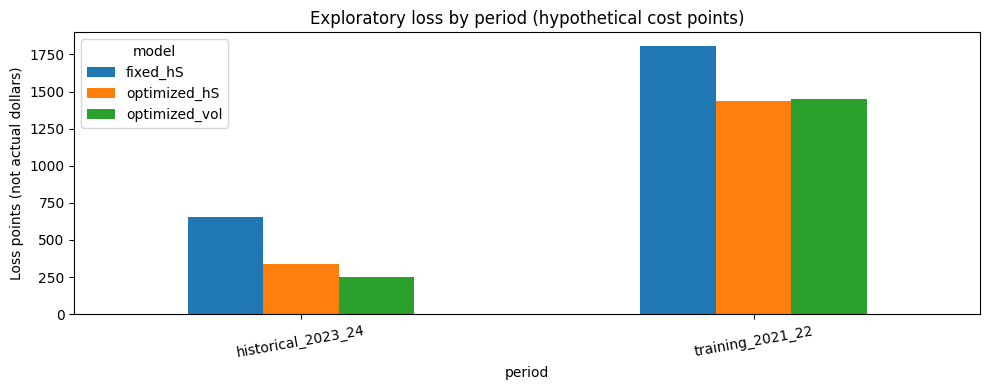

Files: ['cache', 'cost_comparison.png', 'historical_cost_comparison.csv', 'matched_alert_leads.csv', 'monthly_file_manifest.csv', 'selected_rules_2021_2022.json', 'spot_download_manifest.csv', 'training_threshold_grid.csv', 'weight_sensitivity.csv']


In [11]:
import matplotlib.pyplot as plt
if not comparison.empty:
    panel=comparison.pivot(index='period',columns='model',values='cost_points')
    ax=panel.plot(kind='bar',figsize=(10,4),rot=10)
    ax.set_title('Exploratory loss by period (hypothetical cost points)')
    ax.set_ylabel('Loss points (not actual dollars)')
    ax.figure.tight_layout()
    ax.figure.savefig(os.path.join(OUTPUT_DIR,'cost_comparison.png'),dpi=150)
    plt.show()
print('Files:',sorted(os.listdir(OUTPUT_DIR)))

## 11. Output files
I write all files to `MyDrive/btc_lead_cost_results_77months_spot`.

- `spot_download_manifest.csv`: month, URL, SHA-256, size and download status of each spot archive
- `monthly_file_manifest.csv`: period and row count of each monthly raw file
- `cache/BTCUSDT_1m_regularized.parquet`: cleaned one-minute bars
- `cache/btc_signals_1m.parquet`: signals and labels
- `cache/DATA_SOURCE.json`: data source and spot fingerprint of the cache
- `selected_rules_2021_2022.json`: the thresholds I select on 2021–2022
- `training_threshold_grid.csv`: all thresholds and costs on the 2021–22 training period
- `historical_cost_comparison.csv`: fixed and optimized rules by period
- `matched_alert_leads.csv`: alert and lead time for each detected episode
- `weight_sensitivity.csv`: change in the selected thresholds under other hypothetical cost weights
- `cost_comparison.png`: cost comparison figure

This is a retrospective exploratory optimization, distinct from the frozen confirmatory evaluations of 2017–2020 and 2025–2026 in the baseline study; it supports no claim of model superiority, trading profit or actual dollar savings.